In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt

df = pd.read_csv('city_day.csv')
print(df.head())
print(df.info())

        City        Date  PM2.5  PM10     NO    NO2    NOx  NH3     CO    SO2  \
0  Ahmedabad  2015-01-01    NaN   NaN   0.92  18.22  17.15  NaN   0.92  27.64   
1  Ahmedabad  2015-01-02    NaN   NaN   0.97  15.69  16.46  NaN   0.97  24.55   
2  Ahmedabad  2015-01-03    NaN   NaN  17.40  19.30  29.70  NaN  17.40  29.07   
3  Ahmedabad  2015-01-04    NaN   NaN   1.70  18.48  17.97  NaN   1.70  18.59   
4  Ahmedabad  2015-01-05    NaN   NaN  22.10  21.42  37.76  NaN  22.10  39.33   

       O3  Benzene  Toluene  Xylene  AQI AQI_Bucket  
0  133.36     0.00     0.02    0.00  NaN        NaN  
1   34.06     3.68     5.50    3.77  NaN        NaN  
2   30.70     6.80    16.40    2.25  NaN        NaN  
3   36.08     4.43    10.14    1.00  NaN        NaN  
4   39.31     7.01    18.89    2.78  NaN        NaN  
<class 'pandas.DataFrame'>
RangeIndex: 29531 entries, 0 to 29530
Data columns (total 16 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   City

In [2]:
df.isnull().sum()

City              0
Date              0
PM2.5          4598
PM10          11140
NO             3582
NO2            3585
NOx            4185
NH3           10328
CO             2059
SO2            3854
O3             4022
Benzene        5623
Toluene        8041
Xylene        18109
AQI            4681
AQI_Bucket     4681
dtype: int64

In [5]:
df.dropna(inplace=True)

In [9]:
df.columns = df.columns.str.strip()
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')
df = df.dropna(subset=['Date', 'AQI'])
df = df.sort_values('Date')
df.head()

,City,Date,PM2.5,PM10,NO,NO2,NOx,NH3,CO,SO2,O3,Benzene,Toluene,Xylene,AQI,AQI_Bucket
10229,Delhi,2015-01-01,313.22,607.98,69.16,36.39,110.59,33.85,15.20,9.25,41.68,14.36,24.86,9.84,472.0,Severe
10230,Delhi,2015-01-02,186.18,269.55,62.09,32.87,88.14,31.83,9.54,6.65,29.97,10.55,20.09,4.29,454.0,Severe
10231,Delhi,2015-01-03,87.18,131.90,25.73,30.31,47.95,69.55,10.61,2.65,19.71,3.91,10.23,1.99,143.0,Moderate
10232,Delhi,2015-01-04,151.84,241.84,25.01,36.91,48.62,130.36,11.54,4.63,25.36,4.26,9.71,3.34,319.0,Very Poor
10233,Delhi,2015-01-05,146.60,219.13,14.01,34.92,38.25,122.88,9.20,3.33,23.20,2.80,6.21,2.96,325.0,Very Poor


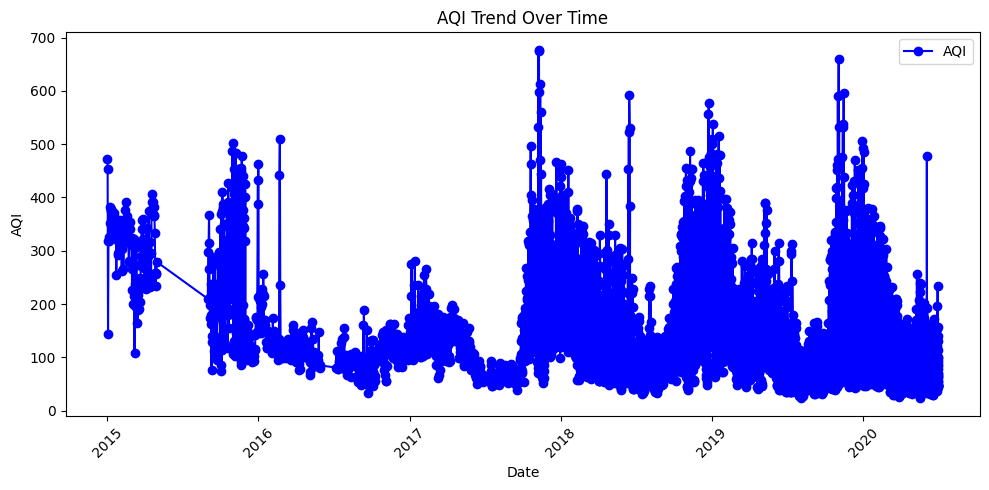

In [10]:
plt.figure(figsize=(10, 5))
plt.plot(df['Date'], df['AQI'], color='blue', marker='o', label='AQI')
plt.xlabel('Date')
plt.ylabel('AQI')
plt.title('AQI Trend Over Time')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


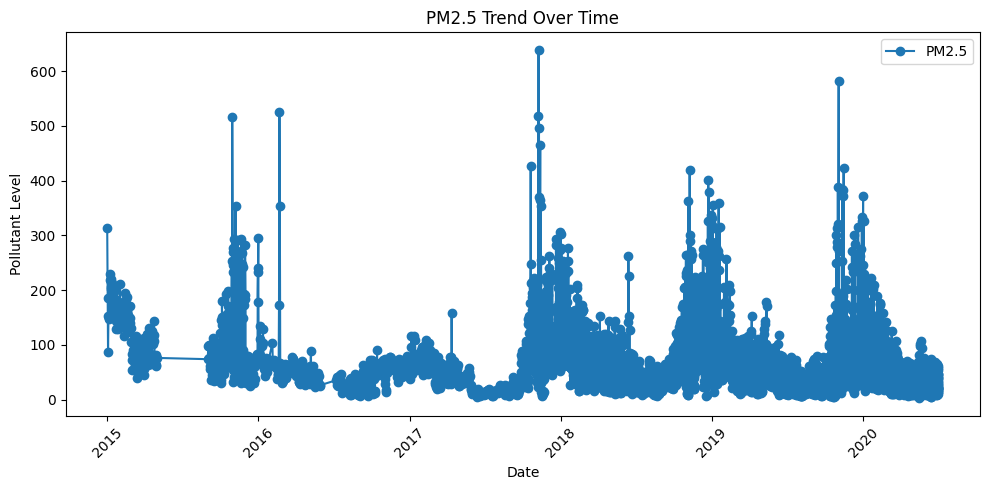

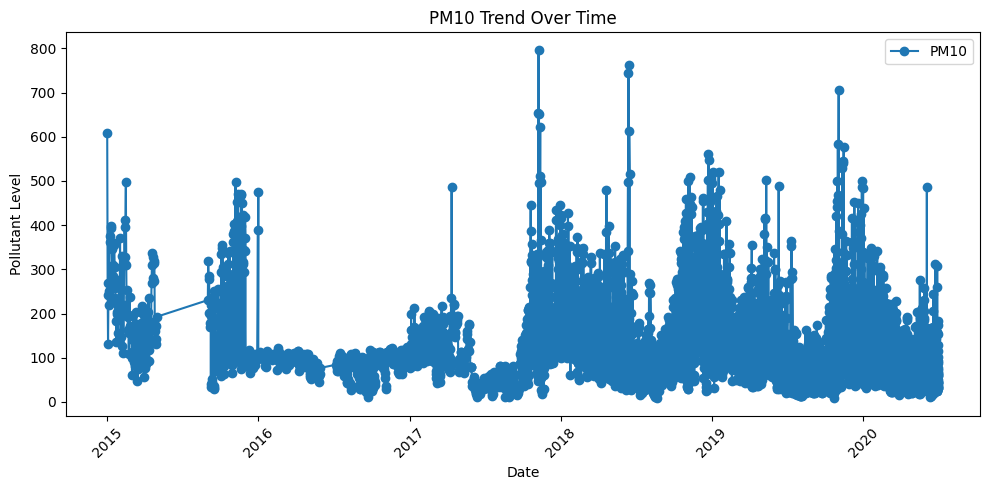

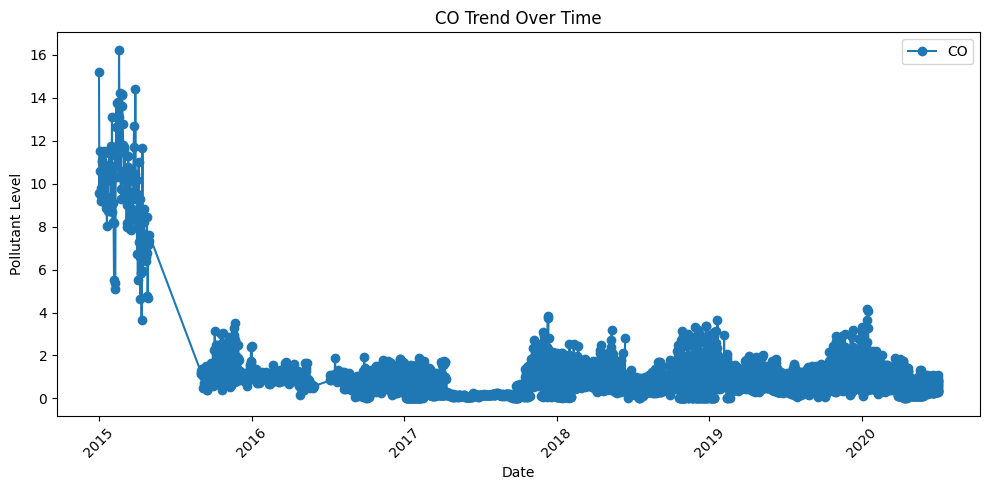

In [11]:
pollutants = ['PM2.5', 'PM10', 'CO']

for pollutant in pollutants:
    if pollutant in df.columns:
        plt.figure(figsize=(10, 5))
        plt.plot(df['Date'], df[pollutant], marker='o', label=pollutant)
        plt.xlabel('Date')
        plt.ylabel('Pollutant Level')
        plt.title(f'{pollutant} Trend Over Time')
        plt.legend()
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

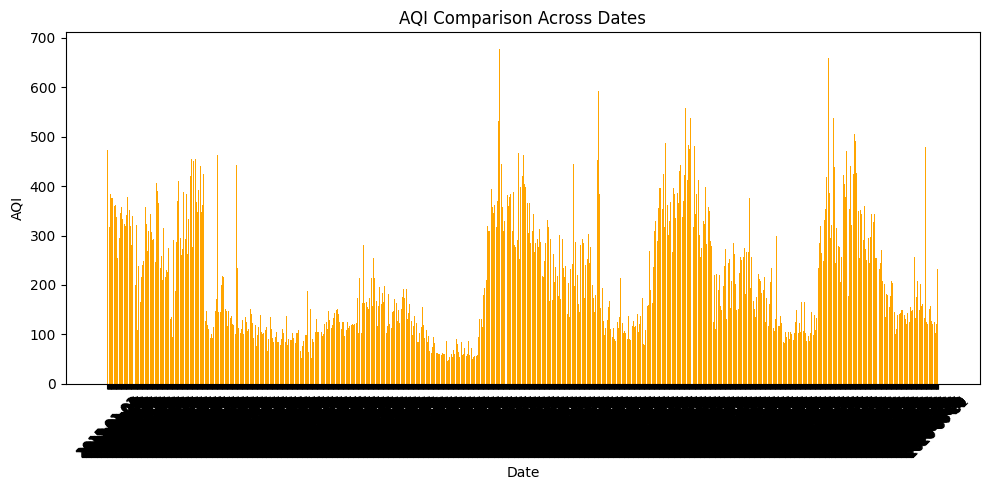

In [12]:
plt.figure(figsize=(10, 5))
plt.bar(df['Date'].dt.strftime('%Y-%m-%d'), df['AQI'], color='orange')
plt.xlabel('Date')
plt.ylabel('AQI')
plt.title('AQI Comparison Across Dates')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

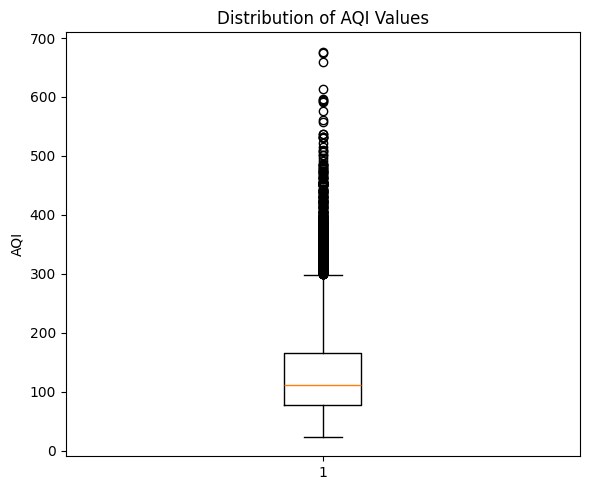

In [13]:
plt.figure(figsize=(6, 5))
plt.boxplot(df['AQI'].dropna())
plt.ylabel('AQI')
plt.title('Distribution of AQI Values')
plt.tight_layout()
plt.show()

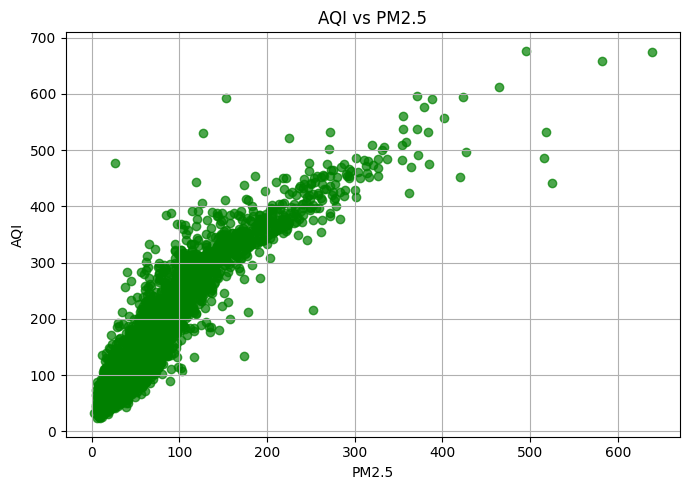

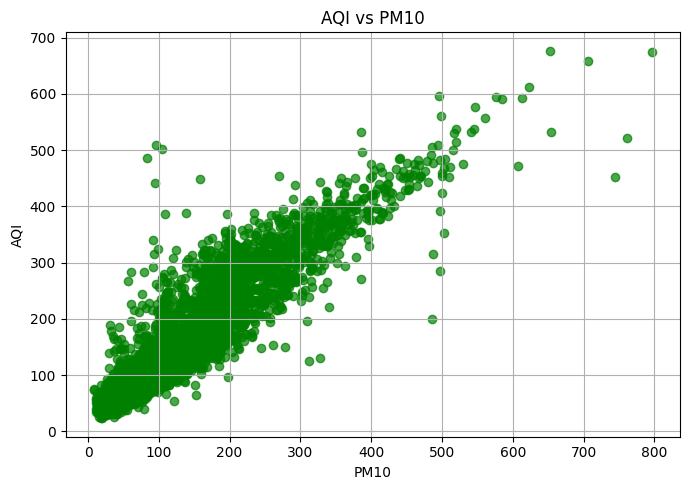

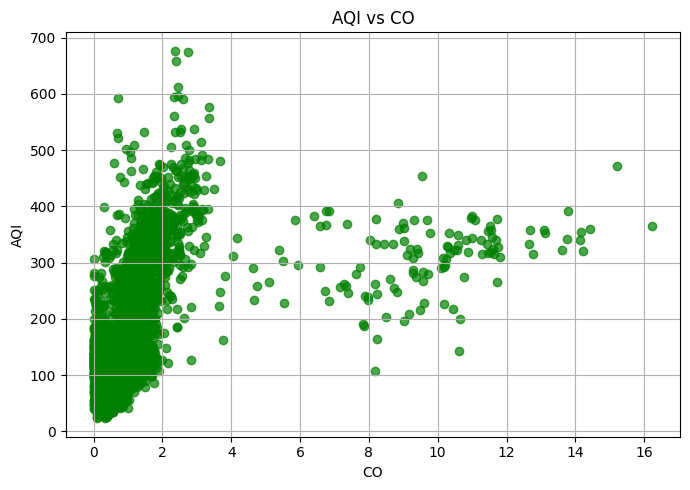

AQI visualization completed successfully.


In [16]:
for pollutant in pollutants:
    if pollutant in df.columns:
        plt.figure(figsize=(7, 5))
        plt.scatter(df[pollutant], df['AQI'], alpha=0.7, color='green')
        plt.xlabel(pollutant)
        plt.ylabel('AQI')
        plt.title(f'AQI vs {pollutant}')
        plt.tight_layout()
        plt.show()
plt.rcParams['figure.figsize'] = (10, 5)
plt.rcParams['axes.grid'] = True

print("AQI visualization completed successfully.")

AQI visualization completed successfully.
